# Movimientos acotados en parpadeo: ¿pueden los cuadros de un movimiento mantener brillante cada trampa en movimiento?

**Pregunta:** ¿Pueden calcularse los hologramas intermedios de un movimiento de modo que cada trampa en movimiento se mantenga brillante, y vale la respuesta para los movimientos largos de un ordenamiento real?

- Nivel: 4, más allá del estado del arte (afirmación BS-2).
- Requisitos previos: `07-feedback-and-dynamics/04-moving-atoms-by-linear-phase-interpolation`, que construye la secuencia de interpolación lineal de fase con la que compara este notebook.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de dos minutos.

## Objetivos

Mover una trampa con un SLM significa mostrar una secuencia de hologramas. Si cada holograma se calcula por separado, las fases libres de las trampas son las que encuentra el algoritmo, saltan de un cuadro al siguiente, y la luz que suman dos puntos vecinos en la posición de un punto en movimiento cambia con ellas: el punto parpadea, y se puede perder un átomo. La interpolación lineal de fase (LPI) evita el salto interpolando las fases entre dos hologramas extremos, pero nunca optimiza los cuadros que crea. B2 optimiza cada cuadro mientras liga las fases de las trampas a una trayectoria suave. Al terminar puedes:

- decir qué está ligado en B2 y qué está libre, y cómo se mueven las posiciones y las fases;
- evaluar dos secuencias distintas con el mismo modelo transitorio;
- medir en la tarea de aceptación de B2 cuánto cae cada secuencia, sobre tres semillas;
- probar la afirmación en un problema más difícil, los 17 movimientos largos del caso C10, y decir qué falla entonces;
- decir qué supone el modelo transitorio.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet, square_grid
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b2_flicker_bounded
from pipeline.model.holo.methods.beyond.b2_flicker_bounded import transient_min_ratio, trajectory
from pipeline.model.holo.methods.control import m16_rearrangement
from pipeline.model.holo.methods.control.m16_rearrangement import assign

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook toma el montaje óptico del caso C10 de `data/examples/cases.json` (256 x 256 píxeles, un bin focal de cerca de 0,5 micrómetros) y construye sobre él la tarea de aceptación de B2. El último paso usa el ordenamiento del propio C10, con su carga y su bloque objetivo.

- Propietario: este repositorio; el caso y la tarea son sintéticos.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C10.

In [2]:
# el caso C10 aporta el montaje óptico y, para el último paso, el ordenamiento de 36 objetivos con 52 átomos
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
bin_m = focal_bin_m(setup)
print(rec["case_id"], "| bin focal", round(bin_m * 1e6, 3), "um | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")

C10_rearrangement | bin focal 0.498 um | SLM 256 x 256 píxeles


## Método

### Cuadros continuos en fase

B2 calcula $S + 1$ cuadros. Las posiciones de las trampas siguen el perfil de mínima sacudida $x_m(s) = x_m(0) + (x_m(S) - x_m(0))\,(10\tau^3 - 15\tau^4 + 6\tau^5)$ con $\tau = s/S$, que parte y termina con velocidad y aceleración cero. Las fases ópticas de las trampas siguen el mismo perfil, $\theta_m(s) = \theta_m(0) + \mathrm{wrap}(\theta_m^\text{fin} - \theta_m(0))\,h(\tau)$, y por defecto se retienen, $\theta^\text{fin} = \theta(0)$. Cada cuadro es un GS ponderado de fase fija (Kim et al., 2019) en el que las amplitudes objetivo son $w_m a_m e^{i\theta_m(s)}$: los pesos $w_m$ se adaptan para que las trampas sean iguales, pero las fases son las de la trayectoria, no libres. El cuadro parte del holograma y de los pesos del cuadro anterior, y ejecuta 10 iteraciones. El método rechaza una secuencia en que la fase se mueve más de 0,3 rad por cuadro.

La intensidad transitoria es un modelo, no una medición. Entre los cuadros $s$ y $s+1$ el campo mostrado se toma como la mezcla $(1 - a)\,e^{i\phi_s} + a\,e^{i\phi_{s+1}}$, con $a$ de 0 a 1, mientras el cristal líquido se relaja, y cada trampa se lee en su posición $x_m(s + a)$. El puntaje de una trampa es su menor intensidad sobre $s$ y $a$ dividida por su media sobre los cuadros. El modelo es la lectura que el pipeline hace del artículo de LPI y está marcado como no verificado en el método; es la misma función para toda secuencia de abajo, así que una comparación con ella es justa aunque sus valores absolutos no lo sean. La primera celda construye la tarea de aceptación de B2: una red de 4 x 4 con espaciado de 8 bins focales cuyas dos columnas de la derecha se mueven 4 bins en x.

In [3]:
# la tarea de aceptación de B2: una red de 4 x 4 a 8 bins focales, las dos columnas de la derecha se mueven
# 4 bins en x
start = square_grid(4, 4, 8 * bin_m * 1e6)
dest = TrapSet(replace(t, x_m=t.x_m + (4 * bin_m if i % 4 >= 2 else 0.0)) for i, t in enumerate(start))
moving = np.array([d.x_m != s.x_m for s, d in zip(start, dest)])
print(f"{len(start)} trampas, {int(moving.sum())} de ellas se mueven {4} bins en x")
print("x de la primera fila, desde y hasta (bins):",
      np.round(start.x_m[:4] / bin_m, 1), np.round(dest.x_m[:4] / bin_m, 1))

16 trampas, 8 de ellas se mueven 4 bins en x
x de la primera fila, desde y hasta (bins): [-12.  -4.   4.  12.] [-12.  -4.   8.  16.]


## Estado del arte

El estado del arte es LPI (la receta de arXiv 2501.01391, implementada en M16): dos hologramas WGS de fase fija, uno para el inicio y otro para el final, la posición, la amplitud y la fase de cada trampa leídas de ellos e interpoladas linealmente, y la transformada inversa en cada paso. La celda lo ejecuta con 12 pasos (13 cuadros, el tamaño del ordenamiento que hace el artículo) para tres semillas, y evalúa los cuadros con el modelo transitorio de B2, con las posiciones que usa LPI, que son lineales en el paso.

In [4]:
# LPI de M16 en 12 pasos, tres semillas; toda secuencia se evalúa con el modelo transitorio de B2, con
# posiciones lineales
lpi = {}
for seed in (1, 2, 3):
    run = m16_rearrangement.run(setup, Target.from_traps(dest), budget=Budget(30), rng=Rng(seed), atoms=start,
                                alpha=1.5, max_step_bins=4 / 12)
    order = run.meta["assignment"]
    origin = TrapSet(replace(t, x_m=start.x_m[order[i]], y_m=start.y_m[order[i]]) for i, t in enumerate(dest))
    along = trajectory(origin, dest, len(run.meta["frames"]), profile=lambda tau: tau)
    lpi[seed] = transient_min_ratio(setup, list(run.meta["frames"]), along)[moving]
for seed, ratio in lpi.items():
    print(f"semilla {seed}: {len(run.meta['frames'])} cuadros | "
          f"menor intensidad transitoria de una trampa en movimiento "
          f"{ratio.min():.3f} | mediana {np.median(ratio):.3f}")

semilla 1: 13 cuadros | menor intensidad transitoria de una trampa en movimiento 0.566 | mediana 0.834
semilla 2: 13 cuadros | menor intensidad transitoria de una trampa en movimiento 0.686 | mediana 0.765
semilla 3: 13 cuadros | menor intensidad transitoria de una trampa en movimiento 0.667 | mediana 0.813


LPI mantiene la trampa en movimiento mediana en 0,834, 0,765 y 0,813 de su media, pero la peor trampa de cada semilla cae a 0,566, 0,686 y 0,667. Las tres están bajo el 0,7 que informa el artículo para sus trampas en movimiento, y ninguna está cerca de 0,9. Las caídas difieren por semilla porque los dos hologramas extremos son independientes: cada uno tiene sus propias fases libres de las trampas, y la interpolación entre dos conjuntos de fases sin relación pasa por la interferencia que ellos formen. La tabla no dice cómo le iría a un átomo en una caída de 0,57, ya que eso depende de la profundidad de la trampa, que el notebook no modela. B2 fija una meta sobre la caída misma: su escalera de métodos pide un mínimo de al menos 0,9.

## Más allá del estado del arte

### B2 en su tarea de aceptación (BS-2)

La brecha que aborda B2 es que LPI no optimiza los cuadros que crea, de modo que los hologramas intermedios son tan desiguales como los deja la interpolación. La afirmación es que ligar las fases de las trampas a una trayectoria suave y reoptimizar cada cuadro mantiene la menor intensidad transitoria de una trampa en movimiento en o sobre 0,9 de su media. La celda ejecuta B2 en la misma tarea, las mismas tres semillas y 13 cuadros, e imprime la menor intensidad, la mediana y la peor desviación estándar relativa de cualquier cuadro (una verificación de que la optimización de cada cuadro no ha cedido su uniformidad).

In [5]:
# B2 en la misma tarea: 13 cuadros, fases de las trampas ligadas a una trayectoria suave, cada cuadro un WGS
# de fase fija desde el anterior
b2_runs = {}
for seed in (1, 2, 3):
    b2_runs[seed] = b2_flicker_bounded.run(setup, Target.from_traps(start), budget=Budget(30), rng=Rng(seed),
                                           destination=dest)
for seed, res in b2_runs.items():
    ratio = res.meta["transient_ratio"][moving]
    worst_frame = max(h["rel_std"] for h in res.history)
    print(f"semilla {seed}: {res.meta['n_frames']} cuadros | menor intensidad transitoria "
          f"{ratio.min():.3f} | mediana {np.median(ratio):.3f} | peor dispersión de un cuadro {worst_frame:.2f} %")

semilla 1: 13 cuadros | menor intensidad transitoria 0.919 | mediana 0.926 | peor dispersión de un cuadro 0.17 %
semilla 2: 13 cuadros | menor intensidad transitoria 0.920 | mediana 0.932 | peor dispersión de un cuadro 0.11 %
semilla 3: 13 cuadros | menor intensidad transitoria 0.923 | mediana 0.930 | peor dispersión de un cuadro 0.11 %


La figura grafica, ordenada, la menor intensidad transitoria de cada una de las 24 trampas en movimiento (3 semillas por 8) para LPI y para B2, con las rectas en 0,7 y 0,9.

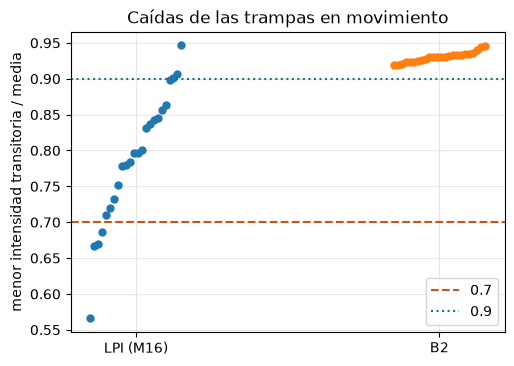

In [6]:
# menor intensidad transitoria de cada trampa en movimiento (3 semillas x 8 trampas), LPI frente a B2
pooled = {"LPI (M16)": np.concatenate(list(lpi.values())),
          "B2": np.concatenate([res.meta["transient_ratio"][moving] for res in b2_runs.values()])}
fig, ax = plt.subplots(figsize=(5.6, 3.9))
for k, (name, values) in enumerate(pooled.items()):
    ax.plot(np.full(values.size, k) + np.linspace(-0.15, 0.15, values.size), np.sort(values), "o", markersize=5)
ax.axhline(0.7, color="#c2571a", linestyle="--", label="0.7")
ax.axhline(0.9, color="#1f6f8b", linestyle=":", label="0.9")
ax.set_xticks([0, 1])
ax.set_xticklabels(list(pooled))
ax.set_ylabel("menor intensidad transitoria / media")
ax.set_title("Caídas de las trampas en movimiento")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

B2 llega a 0,919, 0,920 y 0,923 para la trampa en movimiento más baja en las tres semillas, con medianas de 0,926 a 0,932: toda la columna de B2 queda sobre la recta de 0,9, en una banda angosta, donde los puntos de LPI van de 0,57 a 0,95, cuatro quedan bajo 0,7 y solo unos pocos llegan a 0,9. Los cuadros individuales se mantienen uniformes, con una peor desviación estándar relativa de 0,11 a 0,17 por ciento, de modo que la ganancia no se paga en la calidad de los hologramas. El criterio de aceptación se cumple en las tres semillas, y B2 está sobre LPI en cada una. La figura es para una tarea, en que las trampas se mueven la mitad de un espaciado de red, y para el modelo transitorio del pipeline; no dice que el mismo margen valga para un movimiento más largo, lo que prueba el paso siguiente.

### Un problema más largo: el ordenamiento del caso C10

La tarea de aceptación mueve cada trampa 4 bins. El ordenamiento de C10 mueve átomos hasta 29 bins, y 17 de sus 36 trampas se mueven a la vez, en un campo donde las demás se mantienen. La celda construye el plan con la asignación húngara con exponente 1,0 (el plan sin caminos que se cruzan del notebook anterior), da a cada trampa sus posiciones inicial y final, e imprime cuántas trampas se mueven y el movimiento más largo.

In [7]:
# el ordenamiento del caso C10 (52 átomos a 36 objetivos, alpha = 1.0): las posiciones inicial y final de
# cada trampa
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded, wanted = random_loading(rec), rec["rearrangement"]["target_ids"]
atoms = build.trapset_of([sites[i] for i in loaded])
goal = build.trapset_of([sites[i] for i in wanted])
pick = assign(np.c_[goal.x_m, goal.y_m], np.c_[atoms.x_m, atoms.y_m], 1.0)
origin10 = TrapSet(replace(t, x_m=atoms.x_m[pick[i]], y_m=atoms.y_m[pick[i]]) for i, t in enumerate(goal))
moving10 = np.array([np.hypot(a.x_m - g.x_m, a.y_m - g.y_m) > 0 for a, g in zip(origin10, goal)])
longest = max(np.hypot(a.x_m - g.x_m, a.y_m - g.y_m) for a, g in zip(origin10, goal)) / bin_m
print(f"{len(goal)} trampas, {int(moving10.sum())} en movimiento, movimiento más largo {longest:.1f} bins")

36 trampas, 17 en movimiento, movimiento más largo 29.0 bins


Se mueven diecisiete trampas, la más larga 29,0 bins. B2 tal como está retiene las fases de las trampas del inicio durante todo el movimiento, y al final de un movimiento largo las fases que hacen iguales a las trampas son otras, así que la celda prueba tres secuencias de 25 cuadros: LPI con 24 pasos, B2 con las fases retenidas, y B2 con las fases interpoladas hacia las del holograma final (`end_phases`, el mismo recurso que usa LPI), para lo cual la cota de 0,3 rad por cuadro se relaja a 1,0 rad.

In [8]:
# LPI en 24 pasos, y B2 en 25 cuadros con las fases de las trampas retenidas, y luego con las fases finales
# del holograma final
lpi10 = m16_rearrangement.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1), atoms=atoms,
                              alpha=1.0, max_step_bins=1.25)
along10 = trajectory(origin10, goal, len(lpi10.meta["frames"]), profile=lambda tau: tau)
ratio_lpi = transient_min_ratio(setup, list(lpi10.meta["frames"]), along10)[moving10]
held = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                              destination=goal, frames=25)
final = m07_phase_fixed_wgs.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1))
locked = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                                destination=goal, frames=25, end_phases=np.angle(final.fields),
                                phase_velocity_max=1.0)
stress = {"LPI": ratio_lpi, "B2, fases retenidas": held.meta["transient_ratio"][moving10],
          "B2, fases finales": locked.meta["transient_ratio"][moving10]}
for name, ratio in stress.items():
    print(f"{name:22s} menor {ratio.min():.3f} | mediana {np.median(ratio):.3f} | "
          f"fracción de trampas en movimiento en o sobre 0.7 {np.mean(ratio >= 0.7):.3f}")

LPI                    menor 0.001 | mediana 0.788 | fracción de trampas en movimiento en o sobre 0.7 0.765
B2, fases retenidas    menor 0.000 | mediana 0.009 | fracción de trampas en movimiento en o sobre 0.7 0.000
B2, fases finales      menor 0.379 | mediana 0.730 | fracción de trampas en movimiento en o sobre 0.7 0.588


La figura pone las tres secuencias lado a lado: la menor intensidad y la mediana de las trampas en movimiento a la izquierda, con la recta de 0,7, y la fracción de trampas en o sobre 0,7 a la derecha.

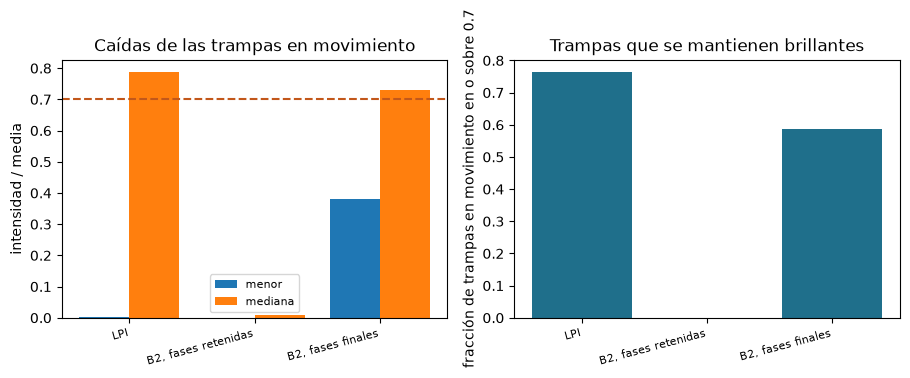

In [9]:
# las tres secuencias del ordenamiento largo: menor intensidad y mediana de las trampas en movimiento, y
# fracción en o sobre 0.7
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.6))
slots = np.arange(len(stress))
a.bar(slots - 0.2, [r.min() for r in stress.values()], 0.4, label="menor")
a.bar(slots + 0.2, [np.median(r) for r in stress.values()], 0.4, label="mediana")
a.axhline(0.7, color="#c2571a", linestyle="--")
b.bar(slots, [np.mean(r >= 0.7) for r in stress.values()], color="#1f6f8b")
for ax in (a, b):
    ax.set_xticks(slots)
    ax.set_xticklabels(list(stress), rotation=15, ha="right", fontsize=8)
a.set_ylabel("intensidad / media")
b.set_ylabel("fracción de trampas en movimiento en o sobre 0.7")
a.legend(fontsize=8)
a.set_title("Caídas de las trampas en movimiento")
b.set_title("Trampas que se mantienen brillantes")
plt.tight_layout()
plt.show()

La afirmación no se traspasa sin cambios. B2 con las fases retenidas colapsa: su trampa en movimiento más baja está en 0,000 y la mediana en 0,009, y ninguna de las trampas en movimiento llega a 0,7, y la causa probable, que el notebook no aisló, es que las fases del inicio no son las que hacen iguales a las trampas al final del movimiento. Darle a B2 las fases finales repara la mayor parte, con un mínimo de 0,379, una mediana de 0,730 y 58,8 por ciento de las trampas en movimiento en o sobre 0,7, pero no supera a LPI en la mediana ni en la fracción: LPI tiene una mediana de 0,788 y 76,5 por ciento de las trampas en movimiento en o sobre 0,7. LPI, sin embargo, tiene la peor trampa de todas, en 0,001, una trampa que casi desaparece en la mezcla entre dos cuadros, y el B2 con fases finales no tiene ninguna tan mala. El resultado es mixto. B2 acota la peor caída en este plan y LPI mantiene más trampas cerca de su media, y ninguno está cerca del 0,9 del movimiento corto. La comparación es de una carga y una semilla, con 25 cuadros cada uno, que el notebook no varió, y se apoya en el modelo transitorio del pipeline.

## Resultados

**Respuesta:** Los hologramas intermedios de un movimiento pueden mantener brillante cada trampa en movimiento cuando el movimiento es corto, y la afirmación no se traspasa a los movimientos largos de un ordenamiento completo. En la tarea de aceptación, 8 de 16 trampas moviéndose 4 bins, B2 tiene una menor intensidad transitoria de 0,919, 0,920 y 0,923 de la media en tres semillas, sobre el 0,9 pedido, frente a 0,566, 0,686 y 0,667 de LPI con el mismo modelo transitorio, con cada cuadro de B2 uniforme a 0,17 por ciento o mejor. En el ordenamiento del caso C10, 17 trampas moviéndose hasta 29,0 bins, B2 con las fases retenidas colapsa a un mínimo de 0,000; con las fases finales llega a un mínimo de 0,379 y una mediana de 0,730 con 58,8 por ciento de las trampas en movimiento en o sobre 0,7, mientras que LPI tiene una mediana de 0,788 y 76,5 por ciento en o sobre 0,7 pero una peor trampa en 0,001.

Lo que el notebook no muestra es una medición con hardware de las caídas, más de una carga, ni la dependencia del número de cuadros más allá de los dos valores usados.

## Resumen

- B2 liga las fases de las trampas a una trayectoria suave y reoptimiza cada cuadro con WGS de fase fija; LPI interpola dos hologramas independientes y no optimiza nada entre ellos.
- Ambos se evalúan aquí con un solo modelo transitorio, que mezcla cuadros consecutivos y no está verificado en términos absolutos.
- En la tarea de aceptación B2 mantiene la trampa en movimiento más baja en 0,919 a 0,923 de su media frente a 0,566 a 0,686 de LPI.
- En los movimientos largos de C10 no se pueden retener las fases del inicio: con las fases finales B2 llega a 0,379 en su peor trampa, y LPI llega a una mediana mayor.
- La afirmación BS-2 vale para movimientos cortos, y su límite es el largo del movimiento respecto del punto.

## Referencias

- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391
- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178